<a href="https://colab.research.google.com/github/kkishore07/DS-SAT-2/blob/main/DS_SAT_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

LOAD DATA

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re

bookings = pd.read_csv("bookings.csv")
facilities = pd.read_csv("facilities.csv")
occupancy = pd.read_csv("occupancy.csv")
calendar = pd.read_csv("calendar.csv")
maintenance = pd.read_csv("maintenance.csv")

print(bookings.shape)
print(facilities.shape)
print(occupancy.shape)
print(calendar.shape)
print(maintenance.shape)

(184, 5)
(20, 4)
(12200, 3)
(61, 4)
(25, 3)


CHECK DATA

In [ ]:
print("Bookings Missing Values")
print(bookings.isnull().sum())

print("\nOccupancy Missing Values")
print(occupancy.isnull().sum())

print("\nCalendar Missing Values")
print(calendar.isnull().sum())

print("\nMaintenance Missing Values")
print(maintenance.isnull().sum())

print("Duplicate bookings:", bookings.duplicated().sum())

Bookings Missing Values
facility    0
date        0
start       0
end         0
purpose     0
dtype: int64

Occupancy Missing Values
timestamp      0
facility       0
count        445
dtype: int64

Calendar Missing Values
date            0
working_day     0
event          57
exam_period     0
dtype: int64

Maintenance Missing Values
facility    0
issue       5
downtime    5
dtype: int64
Duplicate bookings: 4


CLEAN DATA

In [ ]:
def clean_facility_name(x):
    if pd.isna(x):
        return x

    x = re.sub(r'[^A-Z0-9]', '', str(x).upper())

    aliases = {
        "C101": "C101",
        "C102": "C102",
        "C103": "C103",
        "C201": "C201",
        "C202": "C202",
        "C203": "C203",

        "LAB101": "LAB101",
        "LAB102": "LAB102",
        "LAB201": "LAB201",
        "LAB202": "LAB202",
        "LAB301": "LAB301",

        "LIBRARY01": "LIB01",
        "LIB01": "LIB01",

        "AUDITORIUM01": "AUD01",
        "AUD01": "AUD01",

        "SEM01": "SEM01",
        "H101": "H101",
        "H102": "H102",
        "SPORT01": "SPORT01",
        "MEET01": "MEET01",
        "MEET02": "MEET02"
    }

    return aliases.get(x, x)


    for df in [bookings, occupancy, maintenance, facilities]:
        df["facility"] = df["facility"].apply(clean_facility_name)

REMOVE DUPLICATE BOOKINGS


In [ ]:
bookings = bookings.drop_duplicates()

print("Remaining duplicates:",
      bookings.duplicated().sum())

Remaining duplicates: 0


MISSING OCCUPANCY

In [ ]:
occupancy["timestamp"] = pd.to_datetime(
    occupancy["timestamp"]
)

occupancy["hour"] = occupancy["timestamp"].dt.hour
occupancy["date"] = occupancy["timestamp"].dt.date

In [ ]:
print(
    "Missing occupancy:",
    occupancy["count"].isnull().sum()
)

Missing occupancy: 445


In [ ]:
occupancy["count"] = occupancy["count"].fillna(
    occupancy.groupby(
        ["facility", "hour"]
    )["count"].transform("median")
)

Merge Occupancy with Facility Information

In [ ]:
occupancy = occupancy.merge(
    facilities[
        ["facility", "type", "capacity", "block"]
    ],
    on="facility",
    how="left"
)

## FEATURE ENGINEERING

### Utilization Percentage

In [ ]:
occupancy["utilization_pct"] = (
    occupancy["count"] /
    occupancy["capacity"]
) * 100

### Over-Capacity Flag

In [ ]:
occupancy["over_capacity"] = (
    occupancy["count"] >
    occupancy["capacity"]
)

### Day of Week

In [ ]:
occupancy["day_of_week"] = (
    pd.to_datetime(
        occupancy["timestamp"]
    ).dt.day_name()
)

### Weekend Flag

In [ ]:
occupancy["is_weekend"] = (
    pd.to_datetime(
        occupancy["timestamp"]
    ).dt.dayofweek >= 5
)

### Peak Period

In [ ]:
def get_period(hour):

    if 8 <= hour <= 10:
        return "Morning"

    elif 11 <= hour <= 13:
        return "Afternoon"

    elif 14 <= hour <= 16:
        return "Evening"

    else:
        return "Other"

occupancy["period"] = occupancy["hour"].apply(
    get_period
)

Merge Calendar Data

In [ ]:
calendar["date"] = pd.to_datetime(
    calendar["date"]
).dt.date

occupancy["date"] = pd.to_datetime(
    occupancy["timestamp"]
).dt.date

occupancy = occupancy.merge(
    calendar,
    on="date",
    how="left"
)

## Feature Engineering for Bookings

In [ ]:
bookings["date"] = pd.to_datetime(
    bookings["date"]
)

bookings["start"] = pd.to_datetime(
    bookings["start"],
    format="%H:%M"
)

bookings["end"] = pd.to_datetime(
    bookings["end"],
    format="%H:%M"
)

bookings["duration_hours"] = (
    bookings["end"] -
    bookings["start"]
).dt.total_seconds() / 3600

# VISUALIZATION


   facility  average_occupancy  average_utilization  peak_occupancy  \
14   LAB202          28.509836            63.355191            65.0   
15   LAB301          37.183607            61.972678            80.0   
5      C201          43.307377            61.867681            89.0   
12   LAB102          21.333607            60.953162            54.0   
2      C101          36.286656            60.477759            80.0   
4      C103          24.041803            60.104508            60.0   
11   LAB101          23.977759            59.944399            59.0   
13   LAB201          29.546952            59.093904            70.0   
3      C102          29.264754            58.529508            70.0   
7      C203          25.186885            55.970856            63.0   
6      C202          33.210656            55.351093            79.0   
18    LIB02          39.861475            49.826844           100.0   
17    LIB01          58.285008            48.570840           140.0   
21    

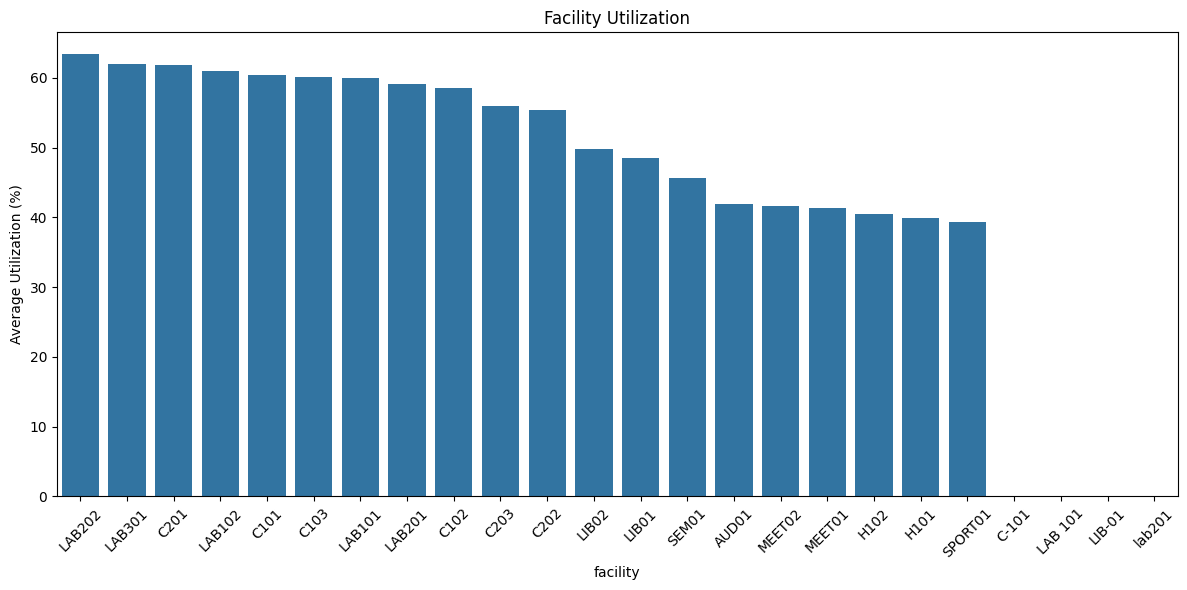

In [ ]:
facility_usage = occupancy.groupby(
    "facility"
).agg(
    average_occupancy=("count", "mean"),
    average_utilization=("utilization_pct", "mean"),
    peak_occupancy=("count", "max"),
    over_capacity_events=("over_capacity", "sum")
).reset_index()

facility_usage = facility_usage.sort_values(
    "average_utilization",
    ascending=False
)

print(facility_usage)


plt.figure(figsize=(12,6))

sns.barplot(
    data=facility_usage,
    x="facility",
    y="average_utilization"
)

plt.xticks(rotation=45)
plt.ylabel("Average Utilization (%)")
plt.title("Facility Utilization")
plt.tight_layout()
plt.show()

   hour  utilization_pct
6    14        52.683431
0     8        52.603953
8    16        52.599538
1     9        52.522627
9    17        52.450366
5    13        52.223307
4    12        52.152378
3    11        52.145262
7    15        52.048689
2    10        51.632654


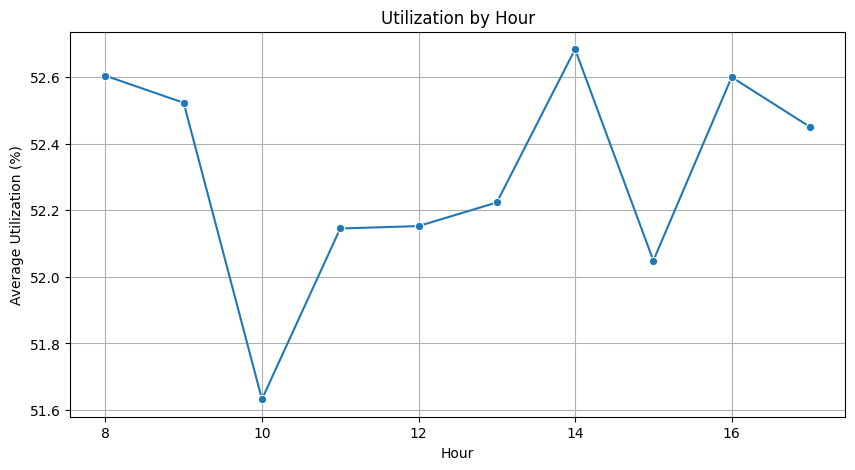

In [ ]:
hourly_usage = occupancy.groupby(
    "hour"
)["utilization_pct"].mean().reset_index()

print(
    hourly_usage.sort_values(
        "utilization_pct",
        ascending=False
    )
)


plt.figure(figsize=(10,5))

sns.lineplot(
    data=hourly_usage,
    x="hour",
    y="utilization_pct",
    marker="o"
)

plt.xlabel("Hour")
plt.ylabel("Average Utilization (%)")
plt.title("Utilization by Hour")
plt.grid()
plt.show()

In [ ]:
underused = facility_usage[
    facility_usage["average_utilization"] < 45
]

print(
    underused.sort_values(
        "average_utilization"
    )
)

   facility  average_occupancy  average_utilization  peak_occupancy  \
22  SPORT01          39.349180            39.349180           120.0   
8      H101          31.940164            39.925205            98.0   
9      H102          24.288525            40.480874            80.0   
19   MEET01           8.262295            41.311475            40.0   
20   MEET02          10.401639            41.606557            42.0   
0     AUD01         125.602459            41.867486           320.0   

    over_capacity_events  
22                    12  
8                      8  
9                     16  
19                    17  
20                    15  
0                     14  


exam_period
0    52.392319
1    51.343589
Name: utilization_pct, dtype: float64


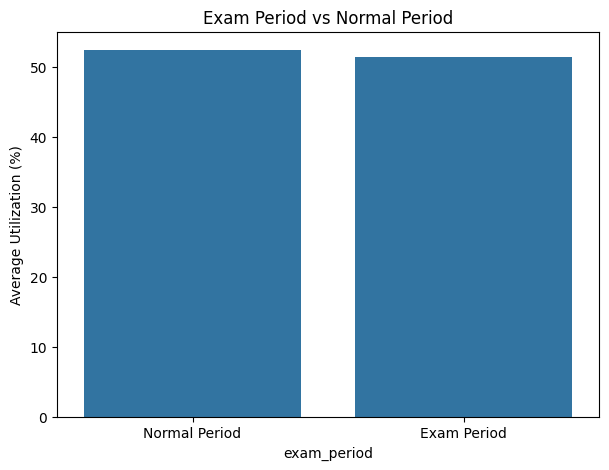

In [ ]:
exam_analysis = occupancy.groupby(
    "exam_period"
)["utilization_pct"].mean()

print(exam_analysis)

plt.figure(figsize=(7,5))

sns.barplot(
    x=exam_analysis.index,
    y=exam_analysis.values
)

plt.xticks(
    [0, 1],
    ["Normal Period", "Exam Period"]
)

plt.ylabel("Average Utilization (%)")
plt.title("Exam Period vs Normal Period")
plt.show()

   facility  downtime
19  SPORT01      24.0
14    LIB01      23.0
12   LAB202      20.0
9    LAB101      15.0
8      H102      13.0
5      C202      12.0
13   LAB301      11.0
2      C102      10.0
10   LAB102       9.0
4      C201       8.0
0     AUD01       8.0
1      C101       8.0
15    LIB02       6.0
6      C203       5.0
3      C103       4.0
18    SEM01       4.0
16   MEET01       3.0
7      H101       0.0
11   LAB201       0.0
17   MEET02       0.0


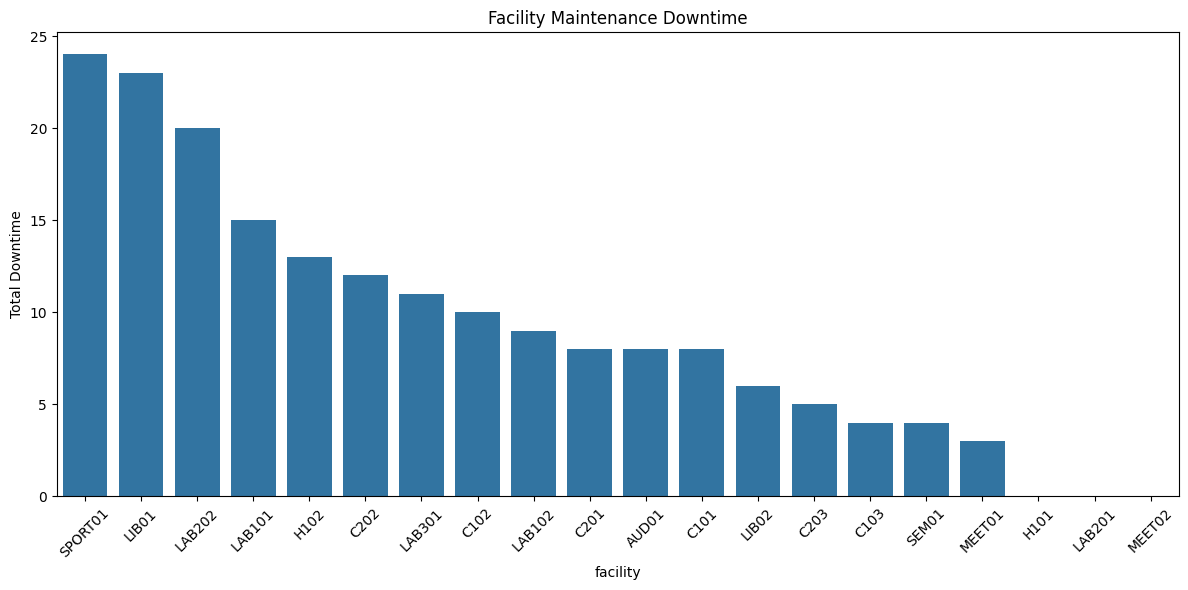

In [ ]:
maintenance["facility"] = (
    maintenance["facility"]
    .apply(clean_facility_name)
)

downtime = maintenance.groupby(
    "facility"
)["downtime"].sum().reset_index()

downtime = downtime.sort_values(
    "downtime",
    ascending=False
)

print(downtime)


plt.figure(figsize=(12,6))

sns.barplot(
    data=downtime,
    x="facility",
    y="downtime"
)

plt.xticks(rotation=45)
plt.ylabel("Total Downtime")
plt.title("Facility Maintenance Downtime")
plt.tight_layout()
plt.show()

   facility  capacity  average_occupancy  peak_occupancy  utilization
0     AUD01     300.0         125.602459           320.0    41.867486
1     C-101       NaN          22.000000            25.0          NaN
2      C101      60.0          36.286656            80.0    60.477759
3      C102      50.0          29.264754            70.0    58.529508
4      C103      40.0          24.041803            60.0    60.104508
5      C201      70.0          43.307377            89.0    61.867681
6      C202      60.0          33.210656            79.0    55.351093
7      C203      45.0          25.186885            63.0    55.970856
8      H101      80.0          31.940164            98.0    39.925205
9      H102      60.0          24.288525            80.0    40.480874
10  LAB 101       NaN          30.666667            51.0          NaN
11   LAB101      40.0          23.977759            59.0    59.944399
12   LAB102      35.0          21.333607            54.0    60.953162
13   LAB201      50.

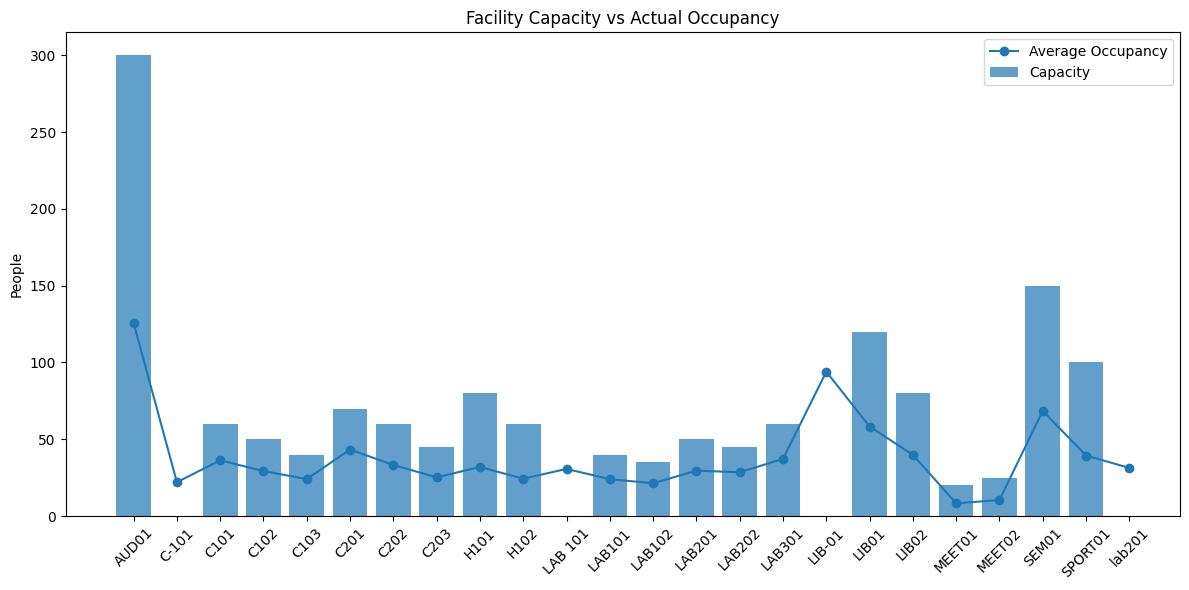

In [ ]:
capacity_analysis = occupancy.groupby(
    "facility"
).agg(
    capacity=("capacity", "first"),
    average_occupancy=("count", "mean"),
    peak_occupancy=("count", "max"),
    utilization=("utilization_pct", "mean")
).reset_index()

print(capacity_analysis)


capacity_violations = occupancy[
    occupancy["over_capacity"] == True
]

print(
    "Total over-capacity events:",
    len(capacity_violations)
)
plt.figure(figsize=(12,6))

plt.bar(
    capacity_analysis["facility"],
    capacity_analysis["capacity"],
    alpha=0.7,
    label="Capacity"
)

plt.plot(
    capacity_analysis["facility"],
    capacity_analysis["average_occupancy"],
    marker="o",
    label="Average Occupancy"
)

plt.xticks(rotation=45)
plt.ylabel("People")
plt.title("Facility Capacity vs Actual Occupancy")
plt.legend()
plt.tight_layout()
plt.show()



In [ ]:
type_usage = occupancy.groupby(
    "type"
)["utilization_pct"].mean().sort_values(
    ascending=False
)

print(type_usage)

type
Laboratory         61.066911
Classroom          58.715457
Library            49.200390
Seminar Hall       45.659016
Auditorium         41.867486
Meeting Room       41.459016
Common Facility    39.918420
Name: utilization_pct, dtype: float64


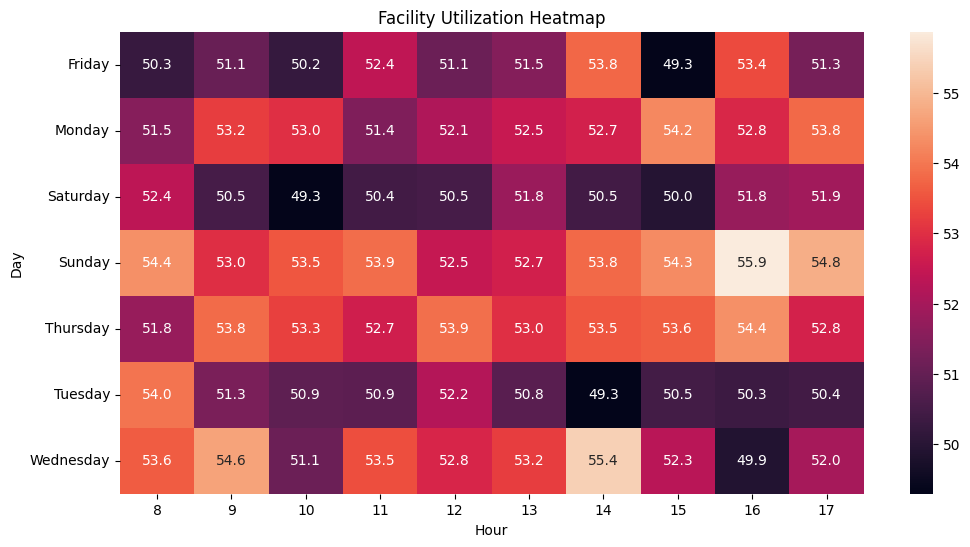

In [ ]:
heatmap_data = occupancy.pivot_table(
    values="utilization_pct",
    index="day_of_week",
    columns="hour",
    aggfunc="mean"
)

plt.figure(figsize=(12,6))

sns.heatmap(
    heatmap_data,
    annot=True,
    fmt=".1f"
)

plt.title(
    "Facility Utilization Heatmap"
)

plt.xlabel("Hour")
plt.ylabel("Day")

plt.show()



SAVE CLEANED DATASETS

In [ ]:



output_folder = Path("cleaned_data")

output_folder.mkdir(
    exist_ok=True
)


bookings.to_csv(
    output_folder / "cleaned_bookings.csv",
    index=False
)

facilities.to_csv(
    output_folder / "cleaned_facilities.csv",
    index=False
)

occupancy.to_csv(
    output_folder / "cleaned_occupancy.csv",
    index=False
)

calendar.to_csv(
    output_folder / "cleaned_calendar.csv",
    index=False
)

maintenance.to_csv(
    output_folder / "cleaned_maintenance.csv",
    index=False
)

facility_summary.to_csv(
    output_folder / "facility_summary.csv",
    index=False
)


Original Shapes
Bookings   : (184, 5)
Facilities : (20, 4)
Occupancy  : (12200, 3)
Calendar   : (61, 4)
Maintenance: (25, 3)

Duplicate bookings before cleaning: 4
Duplicate bookings after cleaning: 0

Missing occupancy before cleaning: 445
Missing occupancy after cleaning: 0

Over-capacity records: 305

CLEANING COMPLETED

Cleaned datasets:
Bookings   : (180, 6)
Facilities : (20, 4)
Occupancy  : (12200, 17)
Calendar   : (61, 4)
Maintenance: (25, 3)

Files saved inside: cleaned_data
